The following data set is from https://www.kaggle.com/code/sonialikhan/body-fat-prediction-dataset-2024 on body fat density

The definition and measurement of density is described in the documentation

In the following we are going to use some Linear Normal Models to describe the data based on the various parameters given in the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

from numpy.ma.core import ones

warnings.filterwarnings('ignore')
data = pd.read_csv ('data/archive/bodyfat.csv')
df = pd.DataFrame (data)
df

,Density,BodyFat,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,1.0708,12.3,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,1.0853,6.1,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,1.0414,25.3,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,1.0751,10.4,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,1.0340,28.7,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,1.0736,11.0,70,134.25,67.00,34.9,89.2,83.6,88.8,49.6,34.8,21.5,25.6,25.7,18.5
248,1.0236,33.6,72,201.00,69.75,40.9,108.5,105.0,104.5,59.6,40.8,23.2,35.2,28.6,20.1
249,1.0328,29.3,72,186.75,66.00,38.9,111.1,111.5,101.7,60.3,37.3,21.5,31.3,27.2,18.0
250,1.0399,26.0,72,190.75,70.50,38.9,108.3,101.3,97.8,56.0,41.6,22.7,30.5,29.4,19.8


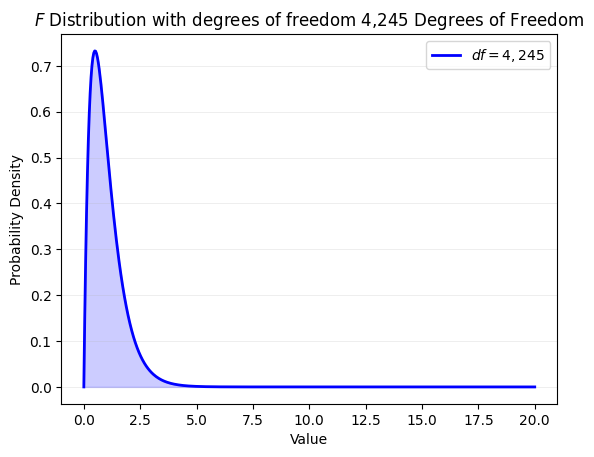

In [2]:
from scipy.stats import f
import matplotlib.pyplot as plt
import numpy as np
samples=250
pf = 5
pr=1

x = np.linspace(0, 20, 500)
y = f.pdf(x, pf-pr,samples-pf)
plt.plot(x, y, label=f'$df = {pf-pr},{samples-pf}$', color='blue', lw=2)
plt.fill_between(x, y, alpha=0.2, color='blue')
    
# Formatting the plot
plt.title(rf'$F$ Distribution with degrees of freedom {pf-pr},{samples-pf} Degrees of Freedom')
plt.xlabel('Value')
plt.ylabel('Probability Density')
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.show()




In [15]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
data = pd.read_csv ('data/archive/bodyfat.csv')
df = pd.DataFrame (data)

n=len(df.Density)
pf=5
pr=1

alpha=0.05

y=df.Density

#Design of Restricted
D_R=np.ones(n).reshape(-1,1)

#Design of Full
D_F=np.column_stack((np.ones(n),df.Height,df.Weight,df.Age,df.Height**2))

#Test statistic
RSS_F=np.linalg.norm(D_F@np.linalg.inv(D_F.T@D_F)@D_F.T@y-y)**2
RSS_R=np.linalg.norm(D_R@np.linalg.inv(D_R.T@D_R)@D_R.T@y-y)**2

T=(RSS_R-RSS_F)/(pf-pr)/(RSS_F/(len(y)-pf))

print(T)

# Critical value
F_CRIT=f.ppf(1-alpha,pf-pr,n-pf)
print(F_CRIT)

if T>=F_CRIT:
    print("H_R rejected go with full")
else:
    print("H_R is just as good")

71.51077918303574
2.408189860091998
H_R rejected go with full
